# PMIP4 continuity in CE 1850

The PMIP3/4/+ `past1000` protocol, which runs from 850-1849 CE (or, in a few cases, to 1850), is distinct from the `historical` protocol, making connecting those simulations somewhat tricky unless the historical simulations used a restart file corresponding to the end of a `past2k/past1000` simulation.

Yet, in some applications it is ncessary to extend `past1000` to the present day, which involves connecting one or more `historical` simulations to their `past1000`counterpart, regardless of the initialization protocol of the `historical runs`.  While most groups were encouraged to do that, some did not have the necessary resources to do so. Occasionally, discrepancies in forcings or initial condition can result in large jumps at the 1850 junction, and the question arises on how to most sensibly minimize those artifacts — without also "correcting" runs that were never actually broken.

This notebook investigates the 1850 discontinuity in 9 GCMs for which we were able to procuse a `past1000`/`past2k` run : ACCESS-ESM1-5, CESM1.1, CESM2, EC-Earth3-Veg-LR, INM-CM4-8, iCESM, MIROC-ES2L, MPI-ESM1-2-LR, MRI-ESM2-0.

**Bottom line, established below:** only **2 of the 9 models actually require an adjustment**: ACCESS-ESM1-5 (flat offset) and CESM2 (linear detrend, an unrelated drift artifact rather than a stitch problem). The other 7 connect cleanly:

* Two simulations were run continuously through the present: __iCESM__ from 850 to 2005 (see [Brady et al (2019)](https://doi.org/10.1029/2019MS001663)) and __CESM1.1__ ran the `past2k` protocol through the present — those 2 simulations have no stitch point at all.
* __MPI-ESM1-2-LR__ also ran `past2k` continuously, but the data in store ends at CE 1849, so it is stitched to a CMIP6 historical run that used a restart file from the end of the past2k run (prefix `r1i2000p1f1`, see Johann Junglaus, personal communication, June 30, 2026) — the 1850 split is a bookkeeping artifact of the archive, not a physical discontinuity.
* The two Japanese models, __MIROC-ES2L__ and __MRI-ESM2-0__, likewise have historical simulations that are `past1000`-aware, with prefixes `r1i1000p1f2` and `r1i1000p1f1` respectively. For MRI-ESM2-0 this meant swapping in a newly-located `r1i1000p1f1` historical run in place of the standard, PiControl-branched `r1i1p1f1` member (see `data_config.yml`).
* __EC-Earth3-Veg-LR__ and __INM-CM4-8__ turn out, on closer inspection, to connect just as cleanly — an earlier mean-matching diagnostic wrongly flagged them for correction (see below for why that diagnostic is the wrong one to use).

We first show why decadal-mean matching is the wrong diagnostic for this problem, then apply the single-year criterion to decide which models actually need correction, and end with a summary that feeds directly into `ce_simul/tas_1850_adjustments.py`, the module that applies these corrections to the full 3-D `tas` fields used elsewhere in the pipeline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
FIGURE_FOLDER = '../results/figures/'

_raw = pd.read_csv('../results/tables/PMIP4_GMST_anomalies.csv', index_col='year', dtype=object)
has_stitch = _raw.loc['has_stitch'].astype(int).astype(bool)   # True = stitched at 1850
gmst = _raw.drop(index='has_stitch').astype(float)
gmst.index = gmst.index.astype(int)

models = sorted(gmst.columns.tolist(), key=str.lower)
gmst = gmst[models]
has_stitch = has_stitch[models]

# Fixed per-model colors, shared across every multi-model figure in this notebook
# (the "All-model overview" plot below establishes the assignment). Figures that
# compare pre- vs. post-1850 segments instead use the dedicated blue/orange scheme.
MODEL_COLORS = {name: color for name, color in zip(models, plt.get_cmap('tab10').colors)}

print(f"{len(models)} models: {models}")
print(f"Year range: {gmst.index[0]} – {gmst.index[-1]}")
print(f"Stitched at 1850: {has_stitch[has_stitch].index.tolist()}")
gmst.tail()

9 models: ['ACCESS-ESM1-5', 'CESM1.1', 'CESM2', 'EC-Earth3-Veg-LR', 'iCESM', 'INM-CM4-8', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0']
Year range: 0 – 2014
Stitched at 1850: ['ACCESS-ESM1-5', 'CESM2', 'EC-Earth3-Veg-LR', 'INM-CM4-8', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0']


,ACCESS-ESM1-5,CESM1.1,CESM2,EC-Earth3-Veg-LR,iCESM,INM-CM4-8,MIROC-ES2L,MPI-ESM1-2-LR,MRI-ESM2-0
year,,,,,,,,,
2010,0.8646,NaN,0.5721,0.8187,NaN,0.6775,0.3335,0.6885,0.6167
2011,0.9132,NaN,0.7562,0.7213,NaN,0.6141,0.6771,0.7630,0.6441
2012,0.9281,NaN,0.9514,0.8470,NaN,0.6137,0.9188,0.7103,0.7203
2013,1.0324,NaN,1.0006,0.7449,NaN,0.6852,0.6400,0.6245,0.7893
2014,1.0178,NaN,0.9435,0.8264,NaN,0.6122,0.4707,0.6871,0.8230


## All-model overview
All PMIP4 models in a single panel; reference period 1951–1980 shaded.

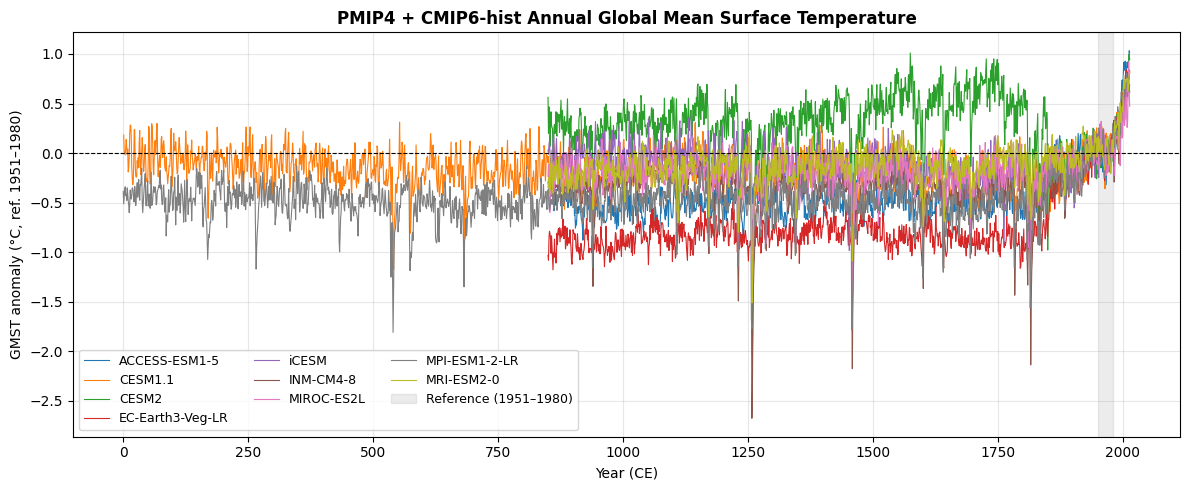

In [2]:
GMST_REF = (1951, 1980)

fig, ax = plt.subplots(figsize=(12, 5))
for name in models:
    s = gmst[name].dropna()
    ax.plot(s.index, s.values, label=name, linewidth=0.8, color=MODEL_COLORS[name])
ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
ax.axvspan(*GMST_REF, color='gray', alpha=0.15, label=f'Reference ({GMST_REF[0]}–{GMST_REF[1]})')
ax.set_xlabel('Year (CE)')
ax.set_ylabel(f'GMST anomaly (°C, ref. {GMST_REF[0]}–{GMST_REF[1]})')
ax.set_title('PMIP4 + CMIP6-hist Annual Global Mean Surface Temperature', fontweight='bold')
ax.legend(fontsize=9, loc='lower left', ncol = 3)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_spaghetti_raw.pdf', bbox_inches='tight',dpi=200)
plt.show()

### Full time series — one panel per model
Vertical dashed line marks the paleo/historical stitch point (1850).

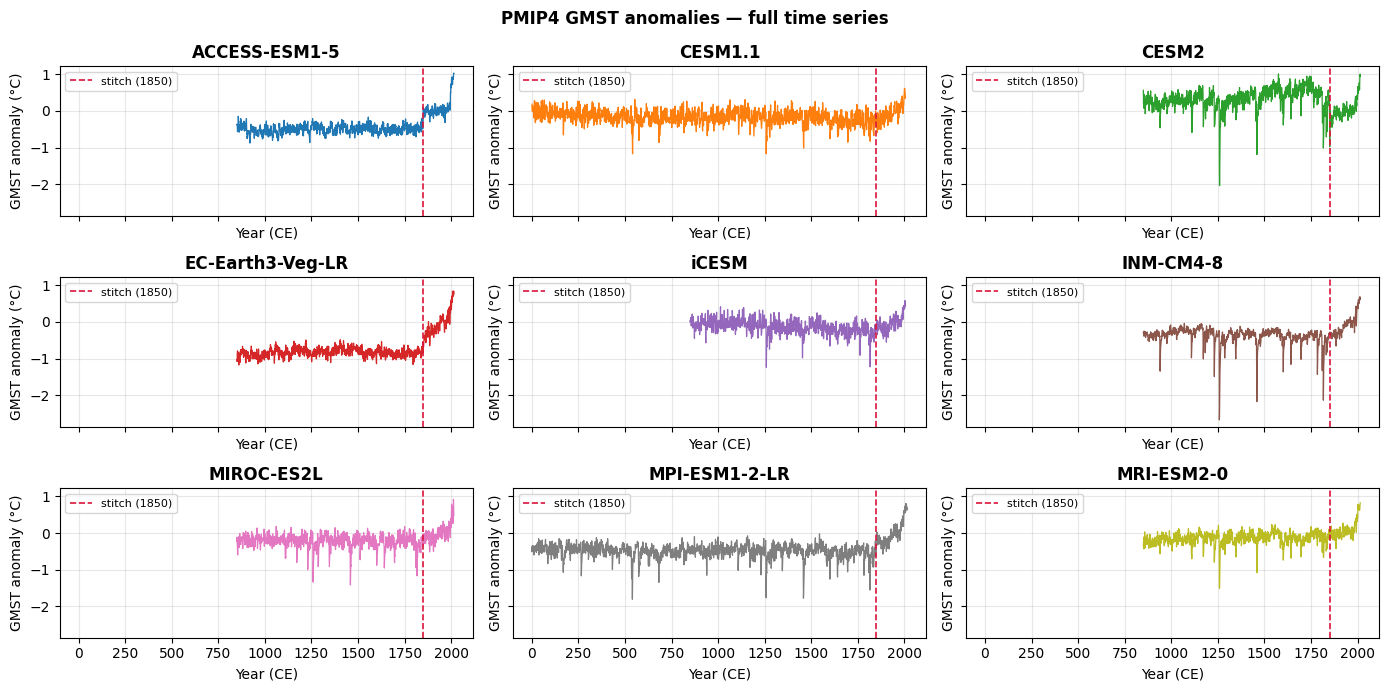

In [3]:
fig, axs = plt.subplots(3, 3, figsize=(14, 7), sharex=True, sharey=True)
axs = axs.ravel()

for ax, name in zip(axs, models):
    s = gmst[name].dropna()
    ax.plot(s.index, s.values, linewidth=0.9, color=MODEL_COLORS[name])
    ax.axvline(1850, color='crimson', linewidth=1.2, linestyle='--', label='stitch (1850)')
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Year (CE)')
    ax.set_ylabel('GMST anomaly (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle('PMIP4 GMST anomalies — full time series', fontweight='bold')
plt.tight_layout()
plt.show()

Visually, 3 models show a suspicious jump: ACCESS-ESM1.5, CESM2, and EC-Earth3. Let's zoom to see that better:

### Zoom around the stitch (1800–1900)
Paleo segment in blue, historical segment in orange; gap/jump at 1850 becomes visible.

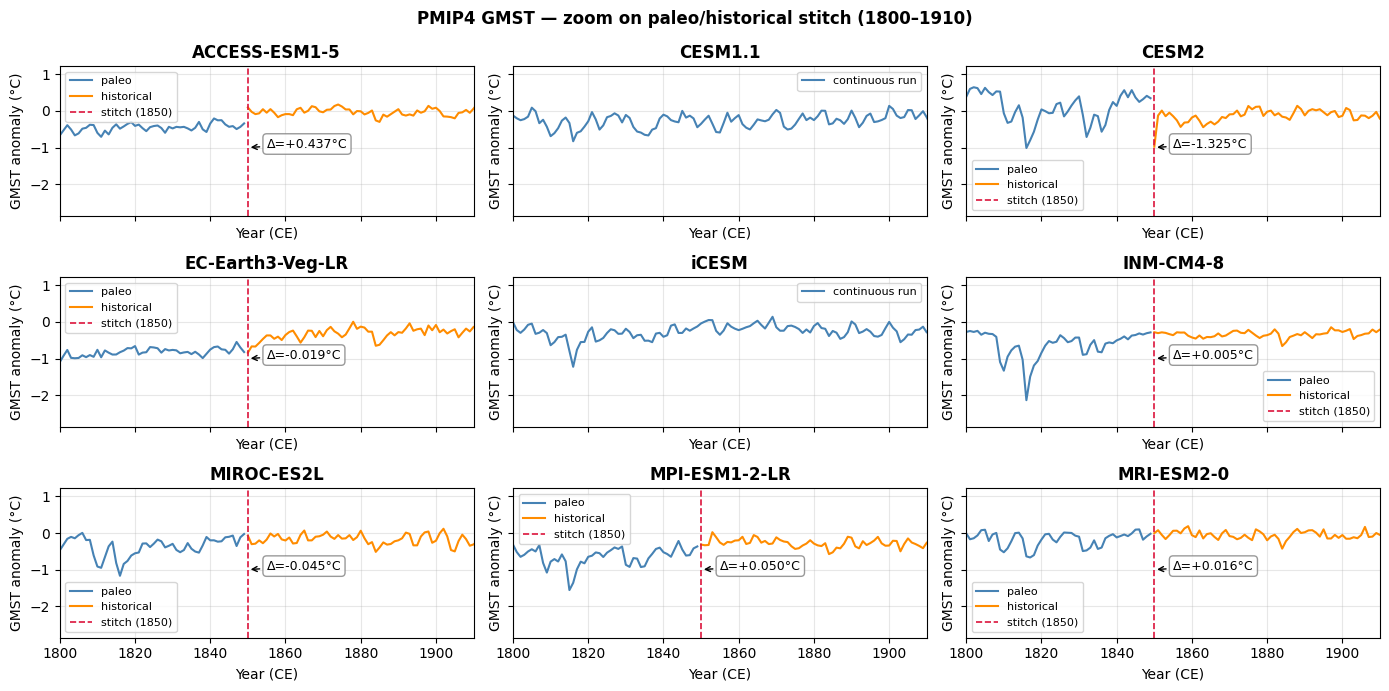

In [4]:
ZOOM = (1800, 1910)
STITCH = 1850

fig, axs = plt.subplots(3, 3, figsize=(14, 7), sharex=True, sharey=True)
axs = axs.ravel()

for ax, name in zip(axs, models):
    s = gmst[name].dropna()

    if has_stitch[name]:
        paleo = s[s.index < STITCH]
        hist  = s[s.index >= STITCH]
        ax.plot(paleo.index, paleo.values, color='steelblue',  linewidth=1.5, label='paleo')
        ax.plot(hist.index,  hist.values,  color='darkorange', linewidth=1.5, label='historical')
        ax.axvline(STITCH, color='crimson', linewidth=1.2, linestyle='--', label='stitch (1850)')
        if len(paleo) and len(hist):
            jump = hist.iloc[0] - paleo.iloc[-1]
            ax.annotate(f'Δ={jump:+.3f}°C',
                        xy=(STITCH, -1),
                        xytext=(STITCH + 5, -1),
                        fontsize=9, color='black',
                        arrowprops=dict(arrowstyle='->', color='black', lw=1),
                        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))
    else:
        ax.plot(s.index, s.values, color='steelblue', linewidth=1.5, label='continuous run')

    ax.set_xlim(ZOOM)
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Year (CE)')
    ax.set_ylabel('GMST anomaly (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

for ax in axs[len(models):]:
    ax.set_visible(False)

plt.suptitle('PMIP4 GMST — zoom on paleo/historical stitch (1800–1910)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_stich_corrections_zoom.pdf', bbox_inches='tight')
plt.show()

The impression persists for those 3 models. Let's quantify the jumps:

### Jump magnitude summary

The single-year difference `v(1850) - v(1849)` for each model — this is the actual restart discontinuity, and (as shown in the next section) the right quantity to correct. 

In [5]:
print(f"{'Model':<22} {'last paleo (1849)':<22} {'first hist (1850)':<22} {'jump (°C)'}")
print('-' * 80)
jump_magnitudes = {}
for name in models:
    s = gmst[name].dropna()
    paleo = s[s.index < 1850]
    hist  = s[s.index >= 1850]
    if paleo.empty or hist.empty:
        print(f"{name:<22}  (incomplete — no stitch)")
        continue
    v_pre  = paleo.iloc[-1]
    v_post = hist.iloc[0]
    jump_magnitudes[name] = v_post - v_pre
    print(f"{name:<22} {v_pre:>10.3f}              {v_post:>10.3f}              {v_post - v_pre:>+.3f}")

Model                  last paleo (1849)      first hist (1850)      jump (°C)
--------------------------------------------------------------------------------
ACCESS-ESM1-5              -0.342                   0.096              +0.437
CESM1.1                    -0.446                  -0.352              +0.094
CESM2                       0.347                  -0.978              -1.325
EC-Earth3-Veg-LR           -0.822                  -0.841              -0.019
iCESM                      -0.123                  -0.039              +0.084
INM-CM4-8                  -0.285                  -0.280              +0.005
MIROC-ES2L                 -0.027                  -0.072              -0.045
MPI-ESM1-2-LR              -0.367                  -0.317              +0.050
MRI-ESM2-0                 -0.020                  -0.004              +0.016


/var/folders/_t/kgsyb8ks4h14w54lv7tgpx6r0000gn/T/ipykernel_79632/2090581855.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(jump_models, rotation=30, ha='right')


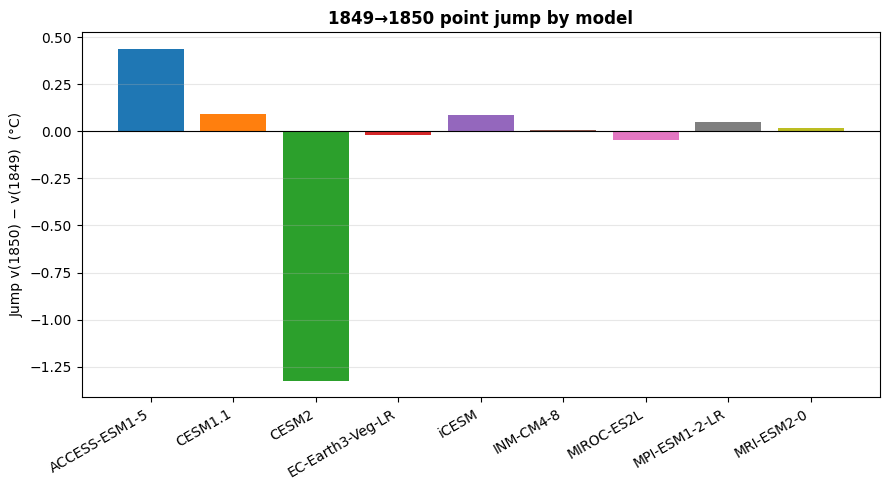

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
jump_models = list(jump_magnitudes.keys())
ax.bar(jump_models, [jump_magnitudes[n] for n in jump_models],
       color=[MODEL_COLORS[n] for n in jump_models])
ax.axhline(0, color='k', linewidth=0.8)
ax.set_xticklabels(jump_models, rotation=30, ha='right')
ax.set_ylabel('Jump v(1850) − v(1849)  (°C)')
ax.set_title('1849→1850 point jump by model', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_jump_magnitudes.pdf', bbox_inches='tight')
plt.show()


Indeed, only ACCESS-ESM1.5 and CESM2 show discontinuities that warrant concern ; the rest are perfectly within the acceptable range of interannual variability (~0.1K).  Now, how should one address these discontinuities? We show two ways to go about it, and pick the most defensible one.

## Choosing the right diagnostic: point jump vs. decadal-mean matching

Our first pass at this problem (an earlier version of this notebook) tried to detect a stitch discontinuity by matching the past1000 segment's 1825-1849 mean to the historical run's 1850-1874 mean, then shifting the whole paleo segment by the difference. That approach was prompted by a question to Johann Junglaus about how PMIP handles the 1850 junction:

> Maybe we did not make it clear enough in the CMIP6 past1000 protocol paper, but groups were requested to carry out one historical run with the end of past1000/past2k as initial condition (using the "restart" file from Dec. 1849). These experiments were marked by a different number in the "ensemble identifier" "i", i.e. in our case r1i2000p1f1. I have seen corresponding "r1f1i1000" experiments from the two Japanese past1000 runs in the CMIP6 archive (MRI-ESM2-0 and MIROC-ES2L) [...] Maybe it would be a good idea to test the stitching methods looking at the differences you get comparing an experiment starting from the "correct" past1000/past2k restart and others starting from some PiControl experiment.
> — Johann Junglaus, pers. comm., 30 June 2026

Testing the mean-matching diagnostic against models expected to need **no** correction (because their historical run is properly restart-branched) showed it was the wrong tool for the job: it kept assigning them sizable "corrections" anyway. The reason is that a 25-year window average mixes the actual restart discontinuity with ordinary internal variability (volcanic recovery, decadal ocean modes, …) that has nothing to do with the stitch. Since what we're trying to detect is a jump introduced at a specific instant, the correct diagnostic is the single-year difference `v(1850) - v(1849)` computed above — not a difference of decadal means.

The comparison below makes this concrete for the 6 models that are stitched but aren't CESM2 (which needs separate handling — see further down).

In [7]:
TOLERANCE = 0.1  # °C; |point offset| within this range is treated as noise, not a real stitch artifact

# All has_stitch models except CESM2, which needs the separate detrend treatment below
STITCHED_MODELS = ['ACCESS-ESM1-5', 'EC-Earth3-Veg-LR', 'INM-CM4-8', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0']

point_offsets = {}
mean_offsets = {}
print(f"{'Model':<22}  {'point offset':<14}  {'mean-based offset':<18}  {'needs correction?'}")
print('-' * 80)
for name in STITCHED_MODELS:
    s = gmst[name].dropna()

    v_1849, v_1850 = s.loc[1849], s.loc[1850]
    point_offsets[name] = v_1850 - v_1849

    pre_mean  = s[(s.index >= 1825) & (s.index < 1850)].mean()
    post_mean = s[(s.index >= 1850) & (s.index < 1875)].mean()
    mean_offsets[name] = post_mean - pre_mean

    flag = 'yes' if abs(point_offsets[name]) > TOLERANCE else 'no'
    print(f"{name:<22}  {point_offsets[name]:>+.4f}         {mean_offsets[name]:>+.4f}              {flag}")

MODELS_TO_CORRECT = [name for name, off in point_offsets.items() if abs(off) > TOLERANCE]
print(f"\nModels requiring a correction under the point criterion (|offset| > {TOLERANCE}°C): {MODELS_TO_CORRECT}")

Model                   point offset    mean-based offset   needs correction?
--------------------------------------------------------------------------------
ACCESS-ESM1-5           +0.4372         +0.4197              yes
EC-Earth3-Veg-LR        -0.0188         +0.3816              no
INM-CM4-8               +0.0045         +0.1731              no
MIROC-ES2L              -0.0452         +0.1448              no
MPI-ESM1-2-LR           +0.0500         +0.3426              no
MRI-ESM2-0              +0.0159         +0.1011              no

Models requiring a correction under the point criterion (|offset| > 0.1°C): ['ACCESS-ESM1-5']


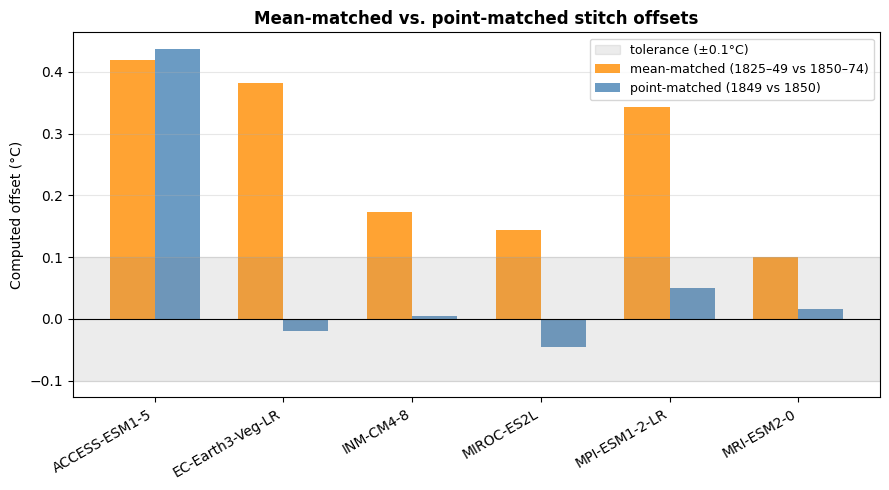

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(STITCHED_MODELS))
width = 0.35
ax.bar(x - width/2, [mean_offsets[n] for n in STITCHED_MODELS], width,
       label='mean-matched (1825–49 vs 1850–74)', color='darkorange', alpha=0.8)
ax.bar(x + width/2, [point_offsets[n] for n in STITCHED_MODELS], width,
       label='point-matched (1849 vs 1850)', color='steelblue', alpha=0.8)
ax.axhline(0, color='k', linewidth=0.8)
ax.axhspan(-TOLERANCE, TOLERANCE, color='gray', alpha=0.15, label=f'tolerance (±{TOLERANCE}°C)')
ax.set_xticks(x)
ax.set_xticklabels(STITCHED_MODELS, rotation=30, ha='right')
ax.set_ylabel('Computed offset (°C)')
ax.set_title('Mean-matched vs. point-matched stitch offsets', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_offset_comparison.pdf', bbox_inches='tight')
plt.show()

**Only ACCESS-ESM1-5 (+0.437°C) exceeds the ±0.1°C tolerance under the point criterion.** Every other stitched model connects cleanly at the single-year boundary: EC-Earth3-Veg-LR (−0.019°C), INM-CM4-8 (+0.005°C), MIROC-ES2L (−0.045°C), MPI-ESM1-2-LR (+0.050°C), MRI-ESM2-0 (+0.016°C) — the last three now confirmed by Johann Junglaus's account of their historical runs' initialization. It is possible that EC-Earth3-Veg-LR and INM-CM4-8 were also in that bucket.

**We thus use the point criterion from here on.** Only ACCESS-ESM1-5 gets a flat offset; CESM2 needs a separate detrend treatment (its issue is a drift, not a boundary jump, and isn't visible in either diagnostic above since it's excluded from `STITCHED_MODELS`).

## Applying the corrections

### ACCESS-ESM1-5
We start with a flat offset for ACCESS-ESM1-5, then move on to CESM2

ACCESS-ESM1-5 flat offset applied to pre-1850 segment: +0.4372 °C


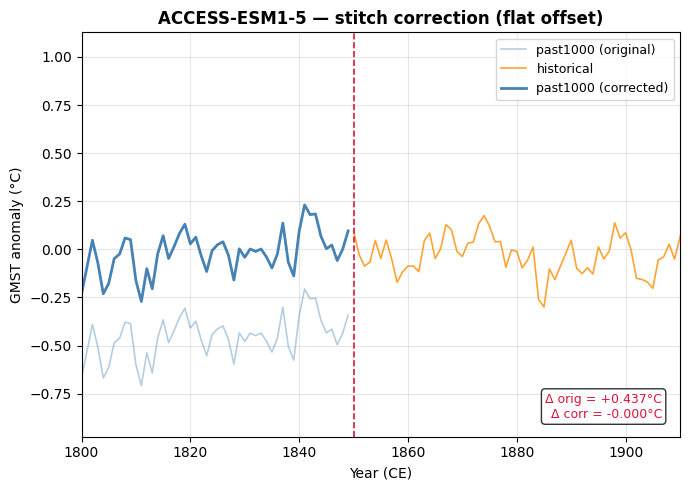

In [9]:
gmst_corrected = gmst.copy()

access_offset = point_offsets['ACCESS-ESM1-5']
mask = gmst_corrected.index < 1850
gmst_corrected.loc[mask, 'ACCESS-ESM1-5'] = gmst_corrected.loc[mask, 'ACCESS-ESM1-5'] + access_offset
print(f"ACCESS-ESM1-5 flat offset applied to pre-1850 segment: {access_offset:+.4f} °C")

# Zoom on the stitch: original vs corrected
orig = gmst['ACCESS-ESM1-5'].dropna()
corr = gmst_corrected['ACCESS-ESM1-5'].dropna()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(orig[orig.index < 1850].index, orig[orig.index < 1850].values,
        color='steelblue', linewidth=1.2, alpha=0.4, label='past1000 (original)')
ax.plot(orig[orig.index >= 1850].index, orig[orig.index >= 1850].values,
        color='darkorange', linewidth=1.2, alpha=0.8, label='historical')
ax.plot(corr[corr.index < 1850].index, corr[corr.index < 1850].values,
        color='steelblue', linewidth=2.0, label='past1000 (corrected)')
ax.axvline(1850, color='crimson', linewidth=1.2, linestyle='--')

v_pre_orig = orig[orig.index < 1850].iloc[-1]
v_post     = orig[orig.index >= 1850].iloc[0]
v_pre_corr = corr[corr.index < 1850].iloc[-1]
ax.text(0.97, 0.04, f'Δ orig = {v_post - v_pre_orig:+.3f}°C\nΔ corr = {v_post - v_pre_corr:+.3f}°C',
        transform=ax.transAxes, fontsize=9, ha='right', va='bottom',
        color='crimson', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlim((1800, 1910))
ax.set_title('ACCESS-ESM1-5 — stitch correction (flat offset)', fontweight='bold')
ax.set_xlabel('Year (CE)')
ax.set_ylabel('GMST anomaly (°C)')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_ACCESS_correction.pdf', bbox_inches='tight')
plt.show()

### CESM2: special handling

**Context (Jiang Zhu, NCAR, pers. comm. 2026-07-01): the run `past1000.002` was initialized from an 850 AD control simulation that included a "background" volcanic emission representing the average 850 AD forcing state. When the `past1000` run started, this background emission was removed and replaced by transient PMIP4 volcanic forcing. The removal of the background forcing acts like a fictitious cooling that then slowly relaxes, producing an artificial **warming drift** throughout the ~1000-year segment — explaining the spurious "warm LIA" visible above, and the large single-year jump (−1.325°C) in the summary table: it's a symptom of the drift, not an independent stitch problem.

The ideal correction is to subtract the drift estimated from the 850 AD control run, but that simulation may no longer be publicly available. Instead, we fit and remove a linear trend directly from the CESM2 `past1000` GMST, then remove the detrended segment's own 850–1849 mean.

In [10]:
cesm2_orig  = gmst['CESM2'].dropna()
cesm2_paleo = cesm2_orig[cesm2_orig.index < 1850]
cesm2_hist  = cesm2_orig[cesm2_orig.index >= 1850]

# Fit and remove linear trend from the past1000 segment
yrs    = cesm2_paleo.index.values.astype(float)
coeffs = np.polyfit(yrs, cesm2_paleo.values, 1)
trend  = np.polyval(coeffs, yrs)

cesm2_detrended = pd.Series(
    cesm2_paleo.values - trend + cesm2_paleo.mean(),
    index=cesm2_paleo.index, name='CESM2'
)

# Align detrended past1000 by removing its own 850-1849 mean, rather than
# matching a noisy 50-yr tail window to the historical run's early mean
cesm2_offset = -cesm2_detrended.mean()
cesm2_corrected_paleo = cesm2_detrended + cesm2_offset

print(f"CESM2 past1000 linear trend:     {coeffs[0]*100:+.4f} °C / century")
print(f"  → total drift (~1000 yr):       {coeffs[0]*1000:+.3f} °C")
print(f"Stitch offset (post-detrend):    {cesm2_offset:+.4f} °C")

# Merge detrended past1000 with historical and update gmst_corrected
cesm2_final = pd.concat([cesm2_corrected_paleo, cesm2_hist])
gmst_corrected['CESM2'] = cesm2_final

CESM2 past1000 linear trend:     +0.0283 °C / century
  → total drift (~1000 yr):       +0.283 °C
Stitch offset (post-detrend):    -0.3255 °C


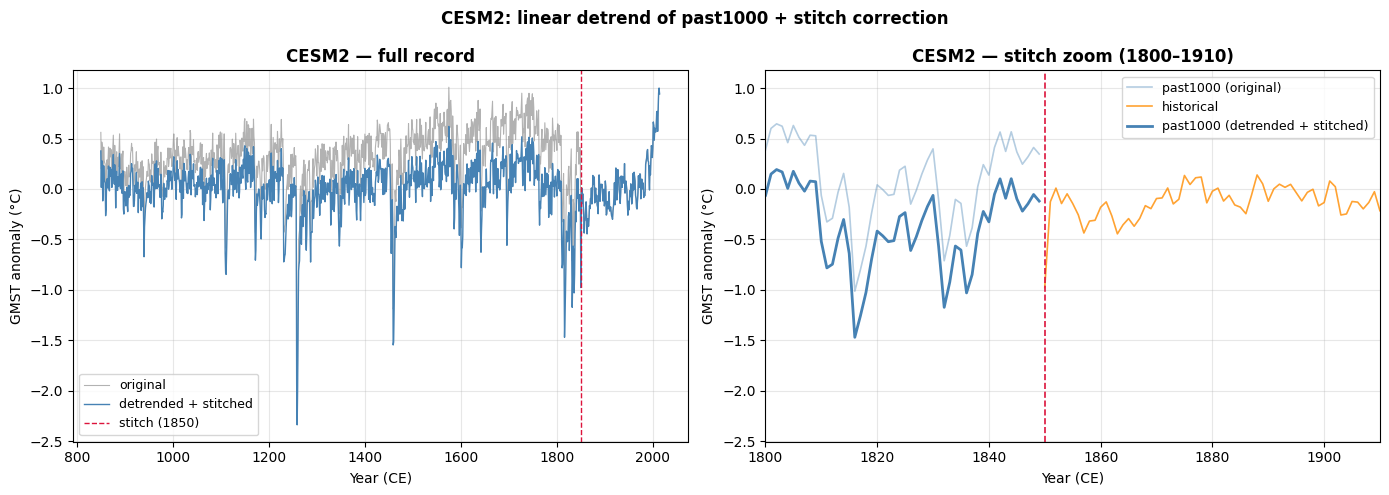

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Full record
cesm2_final = gmst_corrected['CESM2'].dropna()
axs[0].plot(cesm2_orig.index,  cesm2_orig.values,  color='grey',      linewidth=0.8, alpha=0.6, label='original')
axs[0].plot(cesm2_final.index, cesm2_final.values, color='steelblue', linewidth=1.0,            label='detrended + stitched')
axs[0].axvline(1850, color='crimson', linewidth=1.0, linestyle='--', label='stitch (1850)')
axs[0].set_title('CESM2 — full record', fontweight='bold')
axs[0].set_xlabel('Year (CE)')
axs[0].set_ylabel('GMST anomaly (°C)')
axs[0].grid(True, alpha=0.3)
axs[0].legend(fontsize=9)

# Zoom on stitch
axs[1].plot(cesm2_paleo.index,           cesm2_paleo.values,           color='steelblue', linewidth=1.2, alpha=0.4, label='past1000 (original)')
axs[1].plot(cesm2_hist.index,            cesm2_hist.values,            color='darkorange', linewidth=1.2, alpha=0.8, label='historical')
axs[1].plot(cesm2_corrected_paleo.index, cesm2_corrected_paleo.values, color='steelblue',  linewidth=2.0,            label='past1000 (detrended + stitched)')
axs[1].axvline(1850, color='crimson', linewidth=1.2, linestyle='--')
axs[1].set_xlim((1800, 1910))
axs[1].set_title('CESM2 — stitch zoom (1800–1910)', fontweight='bold')
axs[1].set_xlabel('Year (CE)')
axs[1].set_ylabel('GMST anomaly (°C)')
axs[1].grid(True, alpha=0.3)
axs[1].legend(fontsize=9)

plt.suptitle('CESM2: linear detrend of past1000 + stitch correction', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_CESM2_detrend.pdf', bbox_inches='tight')
plt.show()

There is still a sizable jump in 1850, but years before and after are not as jarringly offset.

## All-model overview — post corrections
We now revisit the single-panel view after applying the ACCESS-ESM1-5 offset and the CESM2 detrend. Every other model is shown unmodified — the point-jump criterion above confirmed they don't need it.

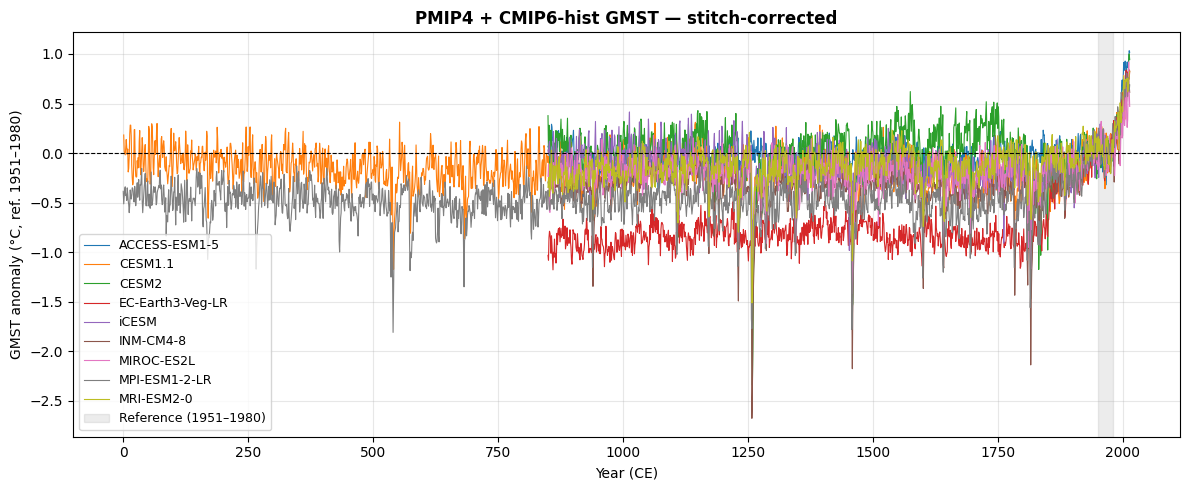

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
for name in models:
    s = gmst_corrected[name].dropna()
    ax.plot(s.index, s.values, label=name, linewidth=0.8, color=MODEL_COLORS[name])
ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
ax.axvspan(*GMST_REF, color='gray', alpha=0.15, label=f'Reference ({GMST_REF[0]}–{GMST_REF[1]})')
ax.set_xlabel('Year (CE)')
ax.set_ylabel(f'GMST anomaly (°C, ref. {GMST_REF[0]}–{GMST_REF[1]})')
ax.set_title('PMIP4 + CMIP6-hist GMST — stitch-corrected', fontweight='bold')
ax.legend(fontsize=9, loc='lower left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_spaghetti_corrected.pdf', bbox_inches='tight')
plt.show()

Note: after detrending and removing the past1000 segment's own 850–1849 mean, CESM2 is closer to the pack but still runs slightly warmer than its closest analogs (CESM1.1, iCESM) over the paleo period. The boreholes will speak on this.

## Summary: adjustments for `ce_simul/tas_1850_adjustments.py`

This is the production-facing result of the notebook. `ce_simul/tas_1850_adjustments.py` applies these same corrections to the full `(year, lat, lon)` `tas` fields (the GMST scalar here is only used to *derive* the correction; the module applies it uniformly across the spatial field). Run `python -m ce_simul.tas_1850_adjustments` any time `results/tables/PMIP4_GMST_anomalies.csv` is regenerated — it recomputes these numbers directly from the CSV, so it can't drift out of sync with this notebook.

The corrections are as follows:

| Model | Adjustment | Value |
|---|---|---|
| **ACCESS-ESM1-5** | flat offset, added to all years < 1850 | **+0.437 °C** |
| **CESM2** | linear detrend of the past1000 segment, then re-centered on its own 850–1849 mean | slope **+0.0283 °C/century**, offset **−0.3255 °C** |
| EC-Earth3-Veg-LR, INM-CM4-8, MIROC-ES2L, MPI-ESM1-2-LR, MRI-ESM2-0 | none — 1849→1850 jump within ±0.1°C tolerance | — |
| CESM1.1, iCESM | none — continuous run, no stitch point | — |

Finally, the cell below cross-checks that `ce_simul.tas_1850_adjustments` reproduces the same numbers as this notebook, directly from the same CSV.

In [13]:
import sys
sys.path.insert(0, '..')
from ce_simul.tas_1850_adjustments import compute_flat_offsets, compute_cesm2_trend, FLAT_OFFSET_MODELS, _load_gmst

prod_gmst = _load_gmst()
prod_offsets = compute_flat_offsets(prod_gmst)
prod_slope, prod_intercept = compute_cesm2_trend(prod_gmst)

print("ce_simul.tas_1850_adjustments cross-check:")
print(f"  FLAT_OFFSET_MODELS: {FLAT_OFFSET_MODELS}")
for name, offset in prod_offsets.items():
    print(f"  {name}: {offset:+.4f} °C  (notebook: {point_offsets[name]:+.4f} °C)")
print(f"  CESM2 trend: {prod_slope*100:+.4f} °C/century  (notebook: {coeffs[0]*100:+.4f} °C/century)")

assert set(FLAT_OFFSET_MODELS) == {'ACCESS-ESM1-5'}
for name, offset in prod_offsets.items():
    assert abs(offset - point_offsets[name]) < 1e-9
assert abs(prod_slope - coeffs[0]) < 1e-9
print("\nOK — production module matches this notebook.")

ce_simul.tas_1850_adjustments cross-check:
  FLAT_OFFSET_MODELS: ['ACCESS-ESM1-5']
  ACCESS-ESM1-5: +0.4372 °C  (notebook: +0.4372 °C)
  CESM2 trend: +0.0283 °C/century  (notebook: +0.0283 °C/century)

OK — production module matches this notebook.
